## Import Libraries and Tools

In [1]:
import os
import numpy as np
import random
import matplotlib.pyplot as plt
import pandas as pd
import PIL.Image as Image
import PIL.ImageEnhance as ImageEnhance

# keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten, Dropout
from tensorflow.keras.utils import load_img
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import VGG16
from sklearn.utils import shuffle


I0000 00:00:1792237217.089368   22132 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792237217.090006   22132 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792237217.124702   22132 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792237218.743175   22132 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

## Local Dataset

In [2]:
train_dir = '/home/nishanta/Projects/MRI_Detection/dataset/Training'
test_dir = '/home/nishanta/Projects/MRI_Detection/dataset/Testing'


# Load and shuffle the train data
train_paths = []
train_labels = []
for label in os.listdir(train_dir):
    for image in os.listdir(os.path.join(train_dir, label)):
        train_paths.append(os.path.join(train_dir, label, image))
        train_labels.append(label)

train_paths, train_labels = shuffle(train_paths, train_labels)


# Load and shuffle the test data
test_paths = []
test_labels = []
for label in os.listdir(test_dir):
    for image in os.listdir(os.path.join(test_dir, label)):
        test_paths.append(os.path.join(test_dir, label, image))
        test_labels.append(label)

test_paths, test_labels = shuffle(test_paths, test_labels)


## Data Visualization

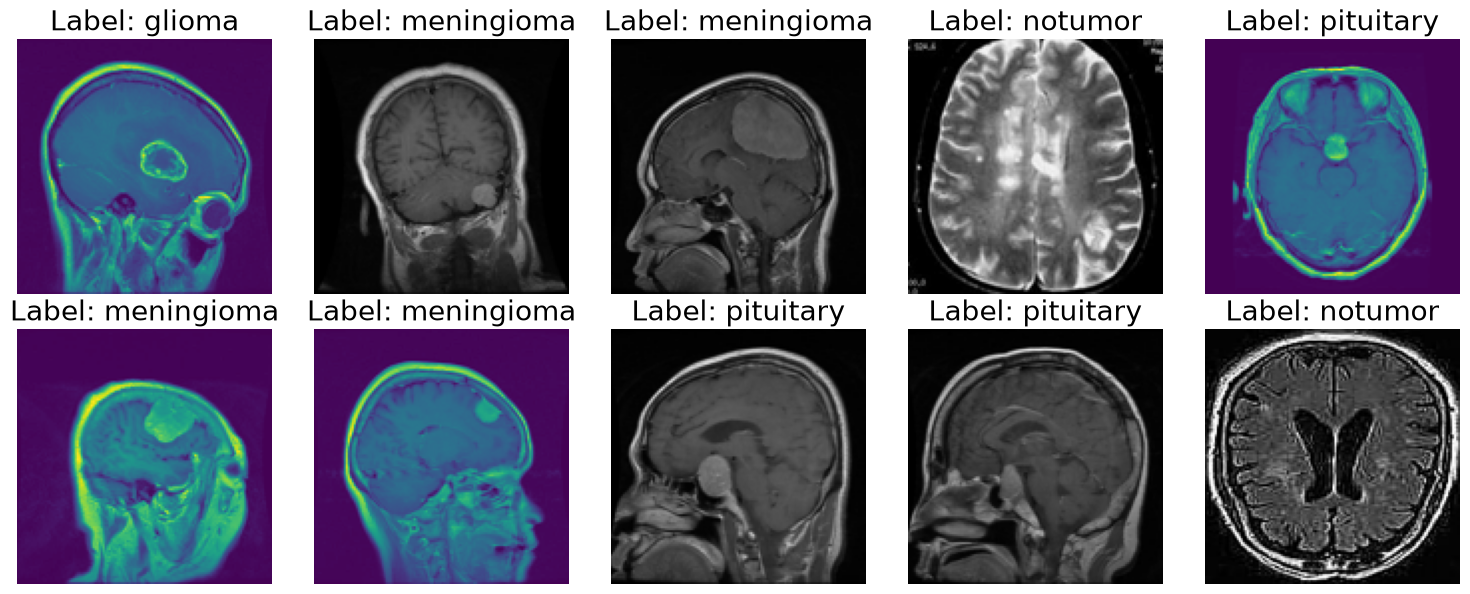

In [3]:
import random
import matplotlib.pyplot as plt

random_indices = random.sample(range(len(train_paths)),10)
random_indices

# Create a figure to display 10 images in 2 rows
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.ravel()

# Loop through the random indices and display the images
for i, idx in enumerate(random_indices):
    img_path = train_paths[idx]
    img = Image.open(img_path)
    img = img.resize((128, 128))  # Resize the image to 128x128

    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(f"Label: {train_labels[idx]}", fontsize=20)

plt.tight_layout()
plt.show()

## Image Preprocessing (Helper Function)

In [6]:
IMAGE_SIZE = 128
# Image augumentation function
def augment_image(image):
    image = Image.fromarray(np.uint8(image)) # convert to PIL image
    image = ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))
    image = ImageEnhance.Contrast(image).enhance(random.uniform(0.8, 1.2))
    image = np.array(image)/255.0 # normalize the image
    return image

# Load images and apply augmentation
def open_images(paths):
    images = []
    for path in paths:
        img = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        img = augment_image(img)
        images.append(img)
    return np.array(images)

# Encoder Labels (Convert label names into integers)
def encode_labels(labels):
    unique_labels = os.listdir(train_dir)
    encoded = [unique_labels.index(label) for label in labels]
    return encoded

# Data generator for batching 
def datagen(paths, labels, batch_size=12, epochs=1):
    for _ in range(epochs):
        for i in range(0, len(paths), batch_size):
            batch_paths = paths[i:i+batch_size]
            batch_images = open_images(batch_paths)
            batch_labels = labels[i:i+batch_size]
            batch_labels = np.asarray(encode_labels(batch_labels), dtype=np.int32)
            yield batch_images, batch_labels

## Model Architecture (VGG16)

In [ ]:
IMAGE_SIZE = 128
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3))

# Freeze all the layers of the VGG16 base model
for layer in base_model.layers:
    layer.trainable = False

# Set only the last few layers to be trainable
base_model.layers[-2].trainable = True
base_model.layers[-3].trainable = True
base_model.layers[-4].trainable = True

# Build the final model
model = Sequential()
model.add(Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))) # Input Layer
model.add(base_model) # VGG16 Base Model
model.add(Flatten()) # Flatten the output of the base model
model.add(Dropout(0.3)) # Dropout layer for regularization

model.add(Dense(128, activation='relu')) # Fully connected layer with 128 units
model.add(Dropout(0.2))

model.add(Dense(len(os.listdir(train_dir)), activation='softmax')) # Output layer with softmax activation for multi-class classification


# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='sparse_categorical_crossentropy', metrics=['sparse_categorical_accuracy'])

# Paramerters for training
batch_size = 20
steps = (len(train_paths) + batch_size - 1) // batch_size
epochs = 5

# train the model
history = model.fit(
    datagen(train_paths, train_labels, batch_size=batch_size, epochs=epochs),
    steps_per_epoch=steps,
    epochs=epochs,
)



Epoch 1/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 343s 1s/step - loss: 0.4723 - sparse_categorical_accuracy: 0.8132
Epoch 2/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 342s 1s/step - loss: 0.2527 - sparse_categorical_accuracy: 0.9016
Epoch 3/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 344s 1s/step - loss: 0.1686 - sparse_categorical_accuracy: 0.9350
Epoch 4/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 1084s 4s/step - loss: 0.1339 - sparse_categorical_accuracy: 0.9477
Epoch 5/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 1373s 5s/step - loss: 0.0941 - sparse_categorical_accuracy: 0.9659


In [ ]:
os.listdir(train_dir)
len(os.listdir(train_dir))

4